<a href="https://colab.research.google.com/github/Siddhartha122/CAR-ML/blob/main/126_ML_day6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mpg,398.0,NaN,NaN,NaN,23.514573,7.815984,9.0,17.5,23.0,29.0,46.6
cylinders,398.0,NaN,NaN,NaN,5.454774,1.701004,3.0,4.0,4.0,8.0,8.0
displacement,398.0,NaN,NaN,NaN,193.425879,104.269838,68.0,104.25,148.5,262.0,455.0
horsepower,392.0,NaN,NaN,NaN,104.469388,38.49116,46.0,75.0,93.5,126.0,230.0
weight,398.0,NaN,NaN,NaN,2970.424623,846.841774,1613.0,2223.75,2803.5,3608.0,5140.0
acceleration,398.0,NaN,NaN,NaN,15.56809,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,NaN,NaN,NaN,76.01005,3.697627,70.0,73.0,76.0,79.0,82.0
origin,398,3,usa,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,398,305,ford pinto,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


,Data Type,Missing Values,Unique Values
mpg,float64,0,129
cylinders,int64,0,5
displacement,float64,0,82
horsepower,float64,6,93
weight,int64,0,351
acceleration,float64,0,95
model_year,int64,0,13
origin,object,0,3
name,object,0,305


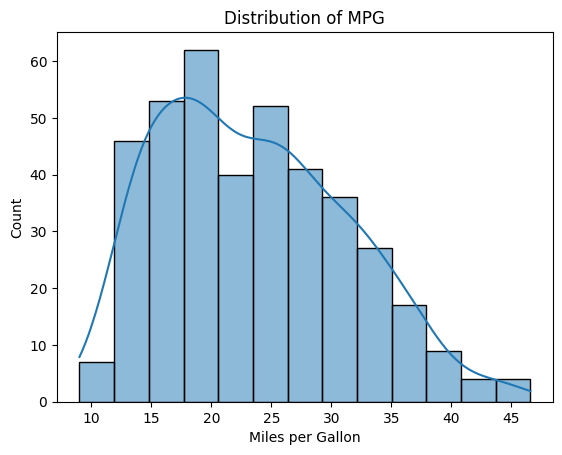

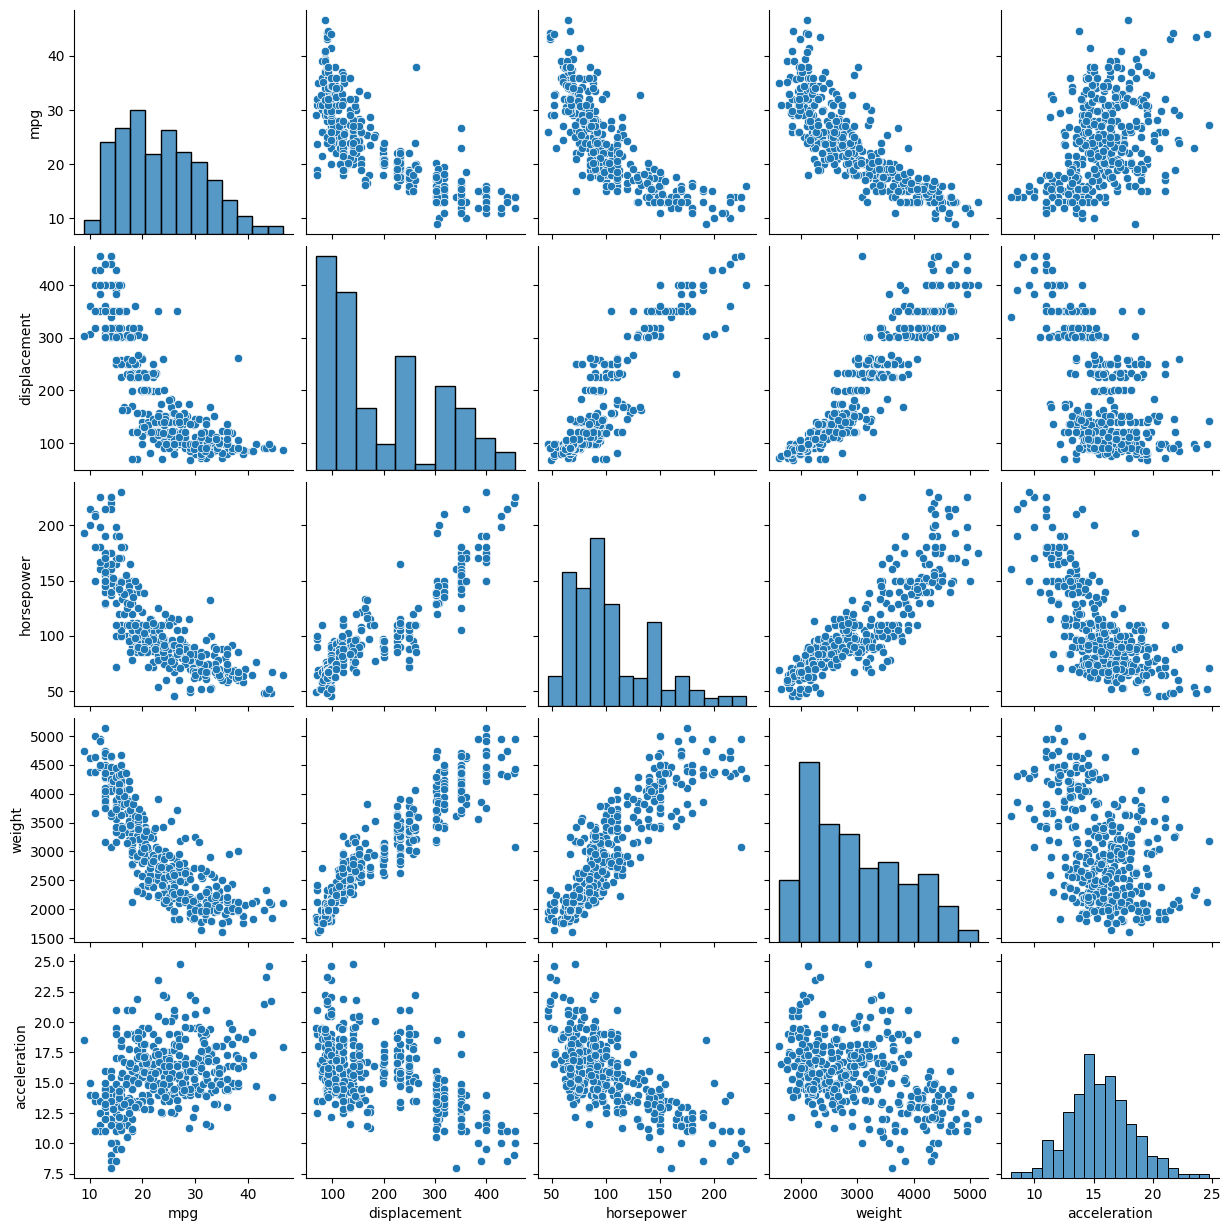

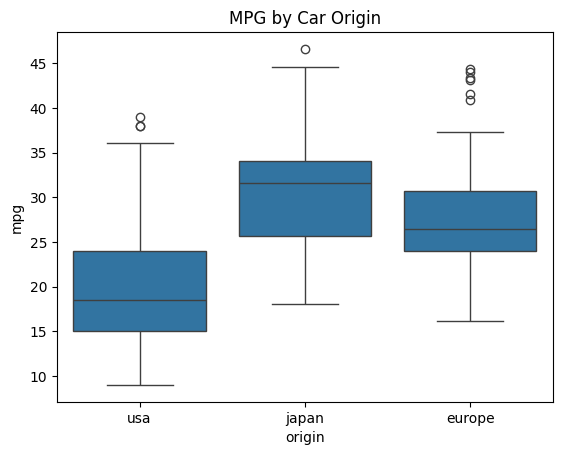

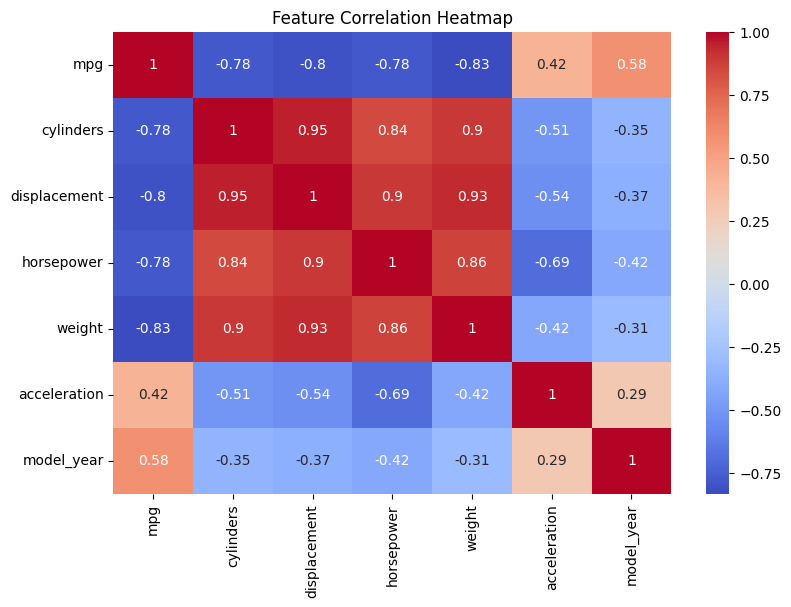

Training rows: 318
Testing rows: 80
Mean CV RMSE: 3.477736410259831
CV RMSE standard deviation: 0.22397202378885678
Test RMSE: 2.887675167561038
Test MAE: 2.28824681388505
Test R2: 0.8449094399450834


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the built-in dataset from Seaborn
df = sns.load_dataset("mpg")

print("Dataset shape:", df.shape)
display(df.head())


df.info()
display(df.describe(include="all").T)
print("Missing values:")
print(df.isna().sum())


missing_table = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Unique Values": df.nunique()
})

display(missing_table)


sns.histplot(df["mpg"], kde=True)
plt.title("Distribution of MPG")
plt.xlabel("Miles per Gallon")
plt.show()


sns.pairplot(df[[
    "mpg", "displacement", "horsepower",
    "weight", "acceleration"
]])
plt.show()

sns.boxplot(data=df, x="origin", y="mpg")
plt.title("MPG by Car Origin")
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Feature Correlation Heatmap")
plt.show()


X = df.drop(columns=["mpg", "name"])
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]
cat_cols = ["origin"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

pre = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

pipe = Pipeline([
    ("pre", pre),
    ("model", LinearRegression())
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rmse = -cross_val_score(
    pipe, X_train, y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("Mean CV RMSE:", cv_rmse.mean())
print("CV RMSE standard deviation:", cv_rmse.std())

pipe.fit(X_train, y_train)

predictions = pipe.predict(X_test)

print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test MAE:", mean_absolute_error(y_test, predictions))
print("Test R2:", r2_score(y_test, predictions))